Dataset: .. _breast_cancer_dataset:
Total Features: 30
Iteration 0: Best Fitness = 0.9696
Iteration 10: Best Fitness = 0.9729
Iteration 20: Best Fitness = 0.9850
Iteration 30: Best Fitness = 0.9850
Iteration 40: Best Fitness = 0.9850

========== FINAL RESULT ==========

Selected Features:
- mean radius
- mean area
- mean concavity
- mean fractal dimension
- smoothness error
- worst radius
- worst texture
- worst smoothness
- worst concave points

Total Features: 30
Selected Features: 9
Removed Features: 21
Best Fitness: 0.985

========== ACCURACY COMPARISON ==========
All Features: 94.74 %
Selected Features: 96.49 %


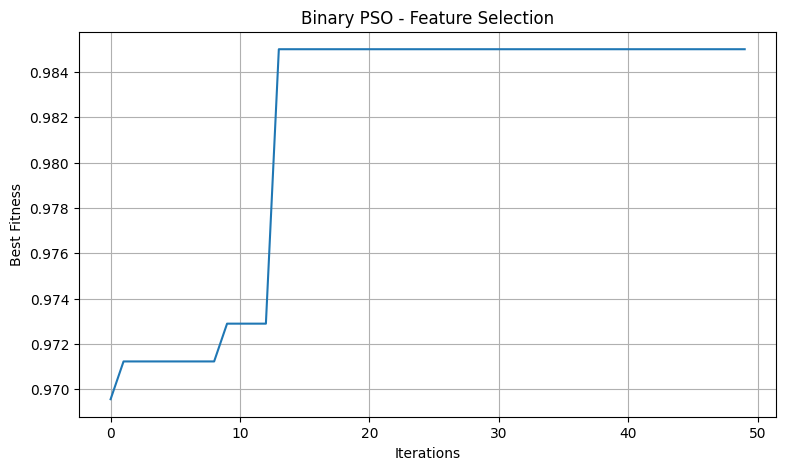

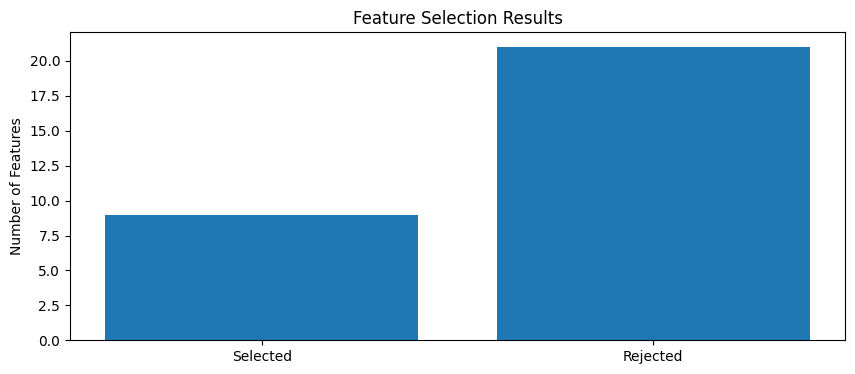

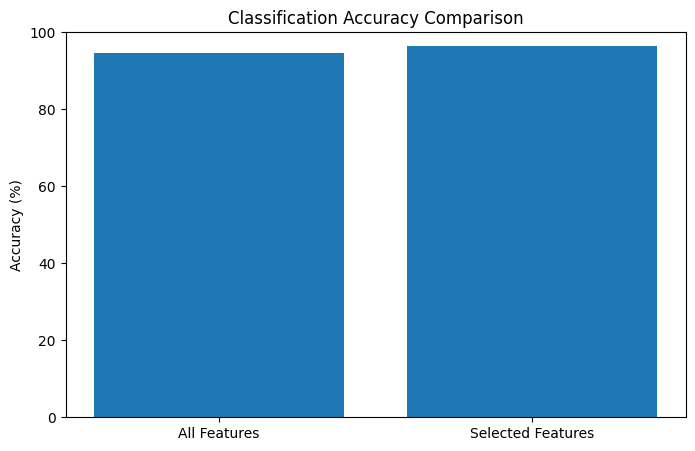

In [13]:
# Binary Particle Swarm Optimization for Feature Selection in Breast Cancer Classification

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


# ==========================================
# 1. LOAD DATASET
# ==========================================

data = load_breast_cancer()

X = data.data
y = data.target

feature_names = data.feature_names
NUM_FEATURES = X.shape[1]

print("Dataset:", data.DESCR.split("\n")[0])
print("Total Features:", NUM_FEATURES)


# ==========================================
# 2. SPLIT DATASET
# ==========================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)


# ==========================================
# 3. PSO PARAMETERS
# ==========================================

NUM_PARTICLES = 20
MAX_ITERATIONS = 50

W = 0.7
C1 = 1.5
C2 = 1.5

PENALTY = 0.05

np.random.seed(42)


# ==========================================
# 4. CLASSIFICATION FUNCTION
# ==========================================

def classify(X_train_selected, X_val_selected):

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )

    model.fit(X_train_selected, y_train)

    predictions = model.predict(X_val_selected)

    return accuracy_score(y_val, predictions)


# ==========================================
# 5. FITNESS FUNCTION
# ==========================================

def fitness(position):

    selected = np.where(position == 1)[0]

    # Avoid empty feature subsets
    if len(selected) == 0:
        return 0

    X_train_selected = X_train[:, selected]
    X_val_selected = X_val[:, selected]

    accuracy = classify(
        X_train_selected,
        X_val_selected
    )

    feature_penalty = len(selected) / NUM_FEATURES

    score = accuracy - PENALTY * feature_penalty

    return score


# ==========================================
# 6. INITIALIZE PARTICLES
# ==========================================

positions = np.random.randint(
    0, 2,
    size=(NUM_PARTICLES, NUM_FEATURES)
)

# Ensure every particle selects at least one feature
for particle in positions:

    if np.sum(particle) == 0:
        particle[np.random.randint(NUM_FEATURES)] = 1


# Initialize velocities
velocities = np.random.uniform(
    -1, 1,
    size=(NUM_PARTICLES, NUM_FEATURES)
)


# ==========================================
# 7. INITIALIZE PERSONAL BEST
# ==========================================

pbest_positions = positions.copy()

pbest_scores = np.array([
    fitness(particle)
    for particle in positions
])


# ==========================================
# 8. INITIALIZE GLOBAL BEST
# ==========================================

best_index = np.argmax(pbest_scores)

gbest_position = pbest_positions[best_index].copy()

gbest_score = pbest_scores[best_index]

history = []


# ==========================================
# 9. BINARY PARTICLE SWARM OPTIMIZATION
# ==========================================

for iteration in range(MAX_ITERATIONS):

    for i in range(NUM_PARTICLES):

        r1 = np.random.random(NUM_FEATURES)
        r2 = np.random.random(NUM_FEATURES)

        # Update velocity
        velocities[i] = (
            W * velocities[i]
            + C1 * r1 * (
                pbest_positions[i] - positions[i]
            )
            + C2 * r2 * (
                gbest_position - positions[i]
            )
        )

        # Calculate sigmoid probability
        sigmoid = 1 / (1 + np.exp(-np.clip(
            velocities[i], -50, 50
        )))

        # Update binary position
        positions[i] = (
            np.random.random(NUM_FEATURES) < sigmoid
        ).astype(int)

        # Ensure at least one feature is selected
        if np.sum(positions[i]) == 0:

            positions[i][
                np.random.randint(NUM_FEATURES)
            ] = 1

        # Evaluate new position
        current_score = fitness(positions[i])

        # Update personal best
        if current_score > pbest_scores[i]:

            pbest_scores[i] = current_score

            pbest_positions[i] = positions[i].copy()

        # Update global best
        if current_score > gbest_score:

            gbest_score = current_score

            gbest_position = positions[i].copy()

    history.append(gbest_score)

    if iteration % 10 == 0:

        print(
            f"Iteration {iteration}: "
            f"Best Fitness = {gbest_score:.4f}"
        )


# ==========================================
# 10. FINAL FEATURE SELECTION
# ==========================================

selected_indices = np.where(
    gbest_position == 1
)[0]

print("\n========== FINAL RESULT ==========")

print("\nSelected Features:")

for index in selected_indices:

    print("-", feature_names[index])

print("\nTotal Features:", NUM_FEATURES)

print("Selected Features:", len(selected_indices))

print("Removed Features:",
      NUM_FEATURES - len(selected_indices))

print("Best Fitness:", round(gbest_score, 4))


# ==========================================
# 11. COMPARE CLASSIFICATION ACCURACY
# ==========================================

# Model using all features
baseline_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)


# Model using selected features
X_train_best = X_train[:, selected_indices]
X_test_best = X_test[:, selected_indices]

optimized_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

optimized_model.fit(X_train_best, y_train)

optimized_predictions = optimized_model.predict(
    X_test_best
)

optimized_accuracy = accuracy_score(
    y_test, optimized_predictions
)


print("\n========== ACCURACY COMPARISON ==========")

print(
    "All Features:",
    round(baseline_accuracy * 100, 2), "%"
)

print(
    "Selected Features:",
    round(optimized_accuracy * 100, 2), "%"
)


# ==========================================
# 12. CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(history)

plt.title("Binary PSO - Feature Selection")
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")

plt.grid()
plt.show()


# ==========================================
# 13. FEATURE SELECTION VISUALIZATION
# ==========================================

plt.figure(figsize=(10, 4))

plt.bar(
    ["Selected", "Rejected"],
    [
        len(selected_indices),
        NUM_FEATURES - len(selected_indices)
    ]
)

plt.title("Feature Selection Results")
plt.ylabel("Number of Features")

plt.show()


# ==========================================
# 14. ACCURACY COMPARISON GRAPH
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["All Features", "Selected Features"],
    [
        baseline_accuracy * 100,
        optimized_accuracy * 100
    ]
)

plt.title("Classification Accuracy Comparison")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

plt.show()